<h3><b>Protocol-Specific Intrusion Detection System for Electric Vehicle Charging Infrastructure using Machine Learning and Hybrid Online Learning</b></h3>

This project builds a smart intrusion detection system for electric vehicle charging networks by combining machine learning with real-time adaptation. First, the data is cleaned and organized to handle imbalance. Then, strong offline models (MLP and Gradient Boosting) are trained, with Gradient Boosting performing best. Next, online models (ARF and SRP with ADWIN) are used to detect attacks in real time while also identifying changes in network behaviuor (drift). Finally, a hybrid model is created by combining the best offline model (Gradient Boosting) with the best online model (ARF), allowing the system to both learn from historical data and adapt continuously, leading to improved detection performance, especially for previously hard-to-detect attack types.

<h4><b>1. Phase 1: Preparing the Dataset</b></h4>

1. Dataset Loading
2. Initial Data Exploration
3. Attack Class Grouping:
    High_Flood (High-Volume Flooding Attacks)
   
    Protocol_Flood (Protocol-Based Flooding Attacks)
   
    Basic_Scan (Basic Network Scanning Attacks)
   
    Advanced_Recon (Advanced Reconnaissance Attacks)
   
5. Family-Level Distribution Analysis
6. Feature–Target Definition
7. Train–Test Split
8. Training Data Distribution Analysis (Before Balancing)
9. Feature Preprocessing
10. Data Transformation
11. Handling Class Imbalance (Balancing)
12. Post-Balancing Analysis


[1] Dataset Loaded
Shape: (1277367, 42)

[2] ORIGINAL CLASS DISTRIBUTION
SYN_Flood: 259481
SynonymousIP_Flood: 256730
TCP_Flood: 256315
PSHACK_Flood: 195952
SYN_Stealth_Scan: 77278
TCP_Port_Scan: 64455
Service_Version_Detection: 46334
Vulnerability_Scan: 38023
UDP_Flood: 32475
OS_Fingerprinting: 26080
Aggressive_Scan: 21762
Slowloris_Scan: 2340
Benign: 82
ICMP_Flood: 32
ICMP_Fragmentation: 28


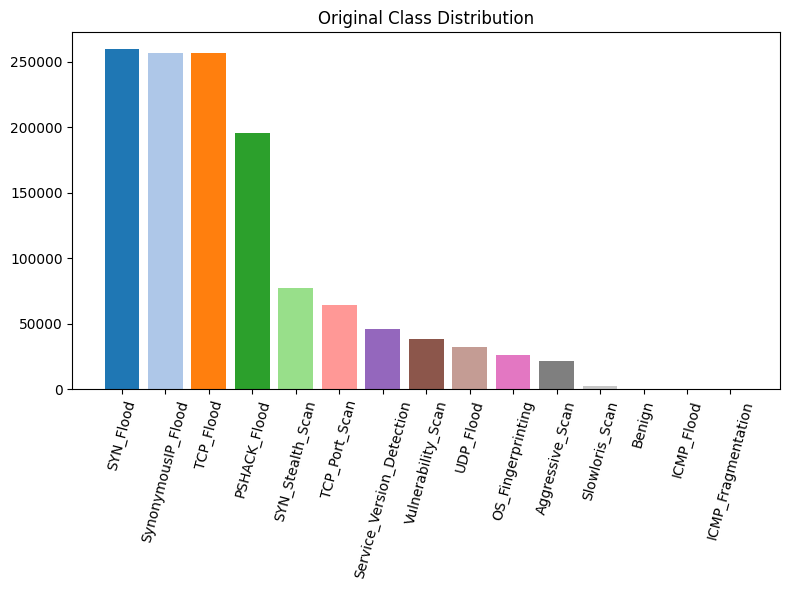


[3] FAMILY DISTRIBUTION
High_Flood: 772526
Protocol_Flood: 228427
Basic_Scan: 163495
Advanced_Recon: 110437


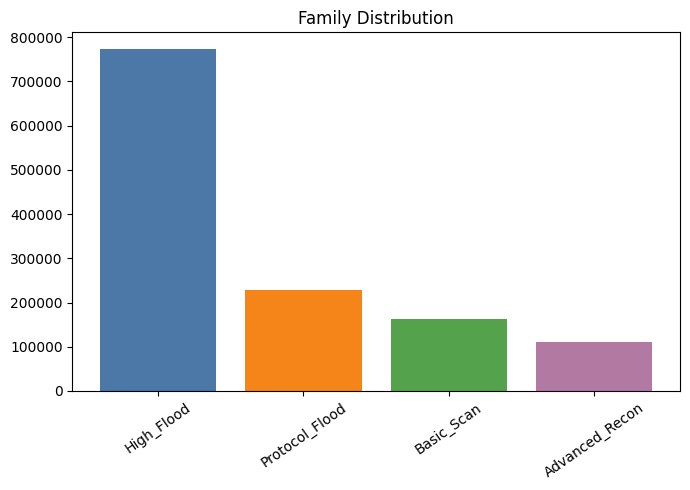


[4] PROTOCOL-SPECIFIC FEATURE SELECTION

Selected protocol-specific features:
1. protocol  -->  Protocol identity feature
2. ip_version  -->  Protocol identity feature
3. bidirectional_first_seen_ms  -->  TCP flag / protocol-behavior feature
4. bidirectional_last_seen_ms  -->  Bidirectional flow-behavior feature
5. bidirectional_duration_ms  -->  Flow-duration feature
6. bidirectional_packets  -->  Packet-count / packet-behavior feature
7. bidirectional_bytes  -->  Byte-volume / traffic-volume feature
8. src2dst_first_seen_ms  -->  TCP flag / protocol-behavior feature
9. src2dst_last_seen_ms  -->  Source-to-destination directional-flow feature
10. src2dst_duration_ms  -->  Flow-duration feature
11. src2dst_packets  -->  Packet-count / packet-behavior feature
12. src2dst_bytes  -->  Byte-volume / traffic-volume feature
13. dst2src_first_seen_ms  -->  TCP flag / protocol-behavior feature
14. dst2src_last_seen_ms  -->  Destination-to-source directional-flow feature
15. dst2src_packets  -

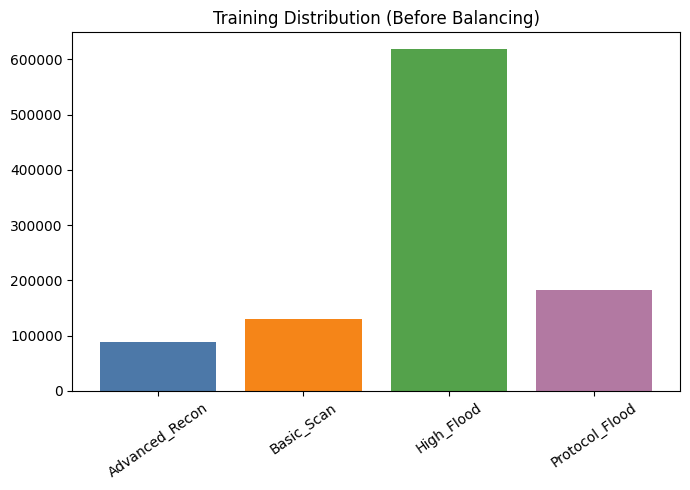


[6] NUMERIC FEATURES USED FOR PREPROCESSING
1. protocol
2. ip_version
3. bidirectional_first_seen_ms
4. bidirectional_last_seen_ms
5. bidirectional_duration_ms
6. bidirectional_packets
7. bidirectional_bytes
8. src2dst_first_seen_ms
9. src2dst_last_seen_ms
10. src2dst_duration_ms
11. src2dst_packets
12. src2dst_bytes
13. dst2src_first_seen_ms
14. dst2src_last_seen_ms
15. dst2src_packets
16. dst2src_bytes
17. bidirectional_min_ps
18. bidirectional_mean_ps
19. bidirectional_max_ps
20. src2dst_min_ps
21. src2dst_mean_ps
22. src2dst_max_ps
23. dst2src_min_ps
24. dst2src_mean_ps
25. dst2src_max_ps
26. bidirectional_min_piat_ms
27. bidirectional_mean_piat_ms
28. bidirectional_stddev_piat_ms
29. bidirectional_max_piat_ms
30. src2dst_min_piat_ms
31. src2dst_mean_piat_ms
32. src2dst_stddev_piat_ms
33. src2dst_max_piat_ms
34. bidirectional_syn_packets
35. bidirectional_ack_packets
36. bidirectional_rst_packets
37. src2dst_syn_packets
38. dst2src_ack_packets
39. dst2src_rst_packets
40. applicati

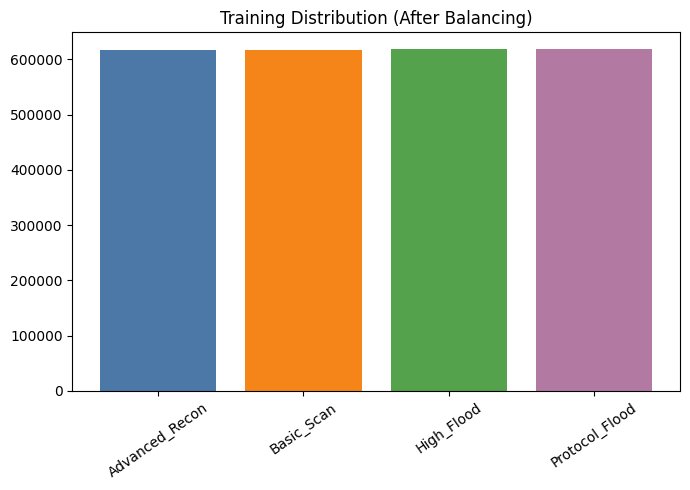


PHASE 1 COMPLETE

Ready variables:
X_train_proc, X_test_proc
y_train, y_test
X_train_bal, y_train_bal
preprocessor, label_encoder
selected_features


In [5]:
# ============================================================
# PHASE 1: LOADING, GROUPING, FEATURE SELECTION, AND PREPROCESSING
# Protocol-Specific IDS Version
# All dataset features are retained as protocol/network-flow features
# Uses SMOTEENN for balancing
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from imblearn.combine import SMOTEENN

# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

DATA_PATH = "/content/CICEVSE2024.csv"
LABEL_COL = "Label"

df = pd.read_csv(DATA_PATH)

print("\n[1] Dataset Loaded")
print(f"Shape: {df.shape}")

# ------------------------------------------------------------
# 2. ORIGINAL CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\n[2] ORIGINAL CLASS DISTRIBUTION")

orig_counts = df[LABEL_COL].value_counts()

for label, count in orig_counts.items():
    print(f"{label}: {count}")

plt.figure(figsize=(8, 6))
colors = plt.cm.tab20(np.linspace(0, 1, len(orig_counts)))
plt.bar(orig_counts.index, orig_counts.values, color=colors)
plt.title("Original Class Distribution")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. DROP RARE CLASSES
# ------------------------------------------------------------

rare_classes = [
    "Benign",
    "ICMP_Flood",
    "ICMP_Fragmentation",
    "Slowloris_Scan"
]

df = df[~df[LABEL_COL].isin(rare_classes)].copy()

# ------------------------------------------------------------
# 4. MAP ATTACKS TO 4 FAMILIES
# ------------------------------------------------------------

def map_family(label):
    if label in ["SYN_Flood", "TCP_Flood", "SynonymousIP_Flood"]:
        return "High_Flood"

    elif label in ["UDP_Flood", "PSHACK_Flood"]:
        return "Protocol_Flood"

    elif label in ["SYN_Stealth_Scan", "TCP_Port_Scan", "Aggressive_Scan"]:
        return "Basic_Scan"

    elif label in ["Service_Version_Detection", "OS_Fingerprinting", "Vulnerability_Scan"]:
        return "Advanced_Recon"

    else:
        return np.nan

df["Family"] = df[LABEL_COL].apply(map_family)
df = df.dropna(subset=["Family"]).copy()

# ------------------------------------------------------------
# 5. FAMILY DISTRIBUTION
# ------------------------------------------------------------

print("\n[3] FAMILY DISTRIBUTION")

family_counts = df["Family"].value_counts()

for fam, count in family_counts.items():
    print(f"{fam}: {count}")

family_colors = ["#4C78A8", "#F58518", "#54A24B", "#B279A2"]

plt.figure(figsize=(7, 5))
plt.bar(family_counts.index, family_counts.values, color=family_colors)
plt.title("Family Distribution")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. PREPARE FEATURES AND TARGET
# ------------------------------------------------------------

X = df.drop(columns=[LABEL_COL, "Family"])
y = df["Family"]

# ------------------------------------------------------------
# 7. PROTOCOL-SPECIFIC FEATURE SELECTION
# ------------------------------------------------------------

print("\n[4] PROTOCOL-SPECIFIC FEATURE SELECTION")

# All the available input features are network-flow/protocol-derived.
# Therefore, all features are retained.
selected_features = X.columns.tolist()

print("\nSelected protocol-specific features:")

for i, feature in enumerate(selected_features, start=1):

    if "protocol" in feature.lower() or "ip_version" in feature.lower():
        category = "Protocol identity feature"

    elif "packet" in feature.lower() or "packets" in feature.lower():
        category = "Packet-count / packet-behavior feature"

    elif "byte" in feature.lower() or "bytes" in feature.lower():
        category = "Byte-volume / traffic-volume feature"

    elif "duration" in feature.lower():
        category = "Flow-duration feature"

    elif "piat" in feature.lower():
        category = "Packet inter-arrival timing feature"

    elif "ps" in feature.lower():
        category = "Packet-size feature"

    elif (
        "syn" in feature.lower()
        or "ack" in feature.lower()
        or "rst" in feature.lower()
        or "fin" in feature.lower()
        or "urg" in feature.lower()
        or "psh" in feature.lower()
    ):
        category = "TCP flag / protocol-behavior feature"

    elif "src2dst" in feature.lower():
        category = "Source-to-destination directional-flow feature"

    elif "dst2src" in feature.lower():
        category = "Destination-to-source directional-flow feature"

    elif "bidirectional" in feature.lower():
        category = "Bidirectional flow-behavior feature"

    elif "application" in feature.lower():
        category = "Application/protocol identification feature"

    else:
        category = "Network-flow derived protocol feature"

    print(f"{i}. {feature}  -->  {category}")

print(f"\nTotal selected features: {len(selected_features)}")

X = X[selected_features].copy()

print(f"Feature matrix shape after feature selection: {X.shape}")

# ------------------------------------------------------------
# 8. ENCODE TARGET
# ------------------------------------------------------------

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("\nTarget Encoding:")

for cls, enc in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{cls}: {enc}")

# ------------------------------------------------------------
# 9. TRAIN-TEST SPLIT
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    stratify=y_encoded,
    random_state=42
)

# ------------------------------------------------------------
# 10. TRAINING SET DISTRIBUTION BEFORE BALANCING
# ------------------------------------------------------------

print("\n[5] TRAINING DISTRIBUTION (BEFORE BALANCING)")

train_counts = pd.Series(y_train).value_counts().sort_index()

for cls, count in train_counts.items():
    print(f"{label_encoder.inverse_transform([cls])[0]}: {count}")

plt.figure(figsize=(7, 5))
labels = label_encoder.inverse_transform(train_counts.index)
plt.bar(labels, train_counts.values, color=family_colors)
plt.title("Training Distribution (Before Balancing)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. PREPROCESSING PIPELINE
# ------------------------------------------------------------

numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()

print("\n[6] NUMERIC FEATURES USED FOR PREPROCESSING")

for i, feature in enumerate(numeric_features, start=1):
    print(f"{i}. {feature}")

preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_features
    )
])

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

print(f"\nX_train_proc shape: {X_train_proc.shape}")
print(f"X_test_proc shape: {X_test_proc.shape}")

# ------------------------------------------------------------
# 12. BALANCING TRAINING SET ONLY
# ------------------------------------------------------------

print("\n[7] APPLYING BALANCING (SMOTEENN)")

smote_enn = SMOTEENN(random_state=42)

X_train_bal, y_train_bal = smote_enn.fit_resample(
    X_train_proc,
    y_train
)

# ------------------------------------------------------------
# 13. TRAINING DISTRIBUTION AFTER BALANCING
# ------------------------------------------------------------

print("\n[8] TRAINING DISTRIBUTION (AFTER BALANCING)")

balanced_counts = pd.Series(y_train_bal).value_counts().sort_index()

for cls, count in balanced_counts.items():
    print(f"{label_encoder.inverse_transform([cls])[0]}: {count}")

plt.figure(figsize=(7, 5))
labels_bal = label_encoder.inverse_transform(balanced_counts.index)
plt.bar(labels_bal, balanced_counts.values, color=family_colors)
plt.title("Training Distribution (After Balancing)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print("\n===================================================")
print("PHASE 1 COMPLETE")
print("===================================================")

print("\nReady variables:")
print("X_train_proc, X_test_proc")
print("y_train, y_test")
print("X_train_bal, y_train_bal")
print("preprocessor, label_encoder")
print("selected_features")

<h4><b>2. Phase 2: Offline Baseline Models</b></h4>

<h5><b>2.1 MLP Model</b></h5>

1. Model set up
2. Model Training
3. Training Loss Monitoring
4. Test Set Prediction
5. Classification Report Generation
6. Performance Evaluation (Macro and Weighted average)
7. Confusion Matrix Visualization


[1] Building MLP model

[2] Training model...
Iteration 1, loss = 0.33206613
Iteration 2, loss = 0.26314498
Iteration 3, loss = 0.20551898
Iteration 4, loss = 0.18528708
Iteration 5, loss = 0.17849851
Iteration 6, loss = 0.15984098
Iteration 7, loss = 0.14933911
Iteration 8, loss = 0.14479970
Iteration 9, loss = 0.15238976
Iteration 10, loss = 0.16144768
Iteration 11, loss = 0.15900281
Iteration 12, loss = 0.15251473
Iteration 13, loss = 0.14234515
Iteration 14, loss = 0.21111223
Iteration 15, loss = 0.16812346
Iteration 16, loss = 0.13326714
Iteration 17, loss = 0.11242328
Iteration 18, loss = 0.13963038
Iteration 19, loss = 0.20558245
Iteration 20, loss = 0.20930431
Iteration 21, loss = 0.20933644
Iteration 22, loss = 0.19687853
Iteration 23, loss = 0.20221838
Iteration 24, loss = 0.20188720
Iteration 25, loss = 0.20320791
Iteration 26, loss = 0.33383852
Iteration 27, loss = 0.30641328
Iteration 28, loss = 0.27008436
Training loss did not improve more than tol=0.000100 for 10 consec

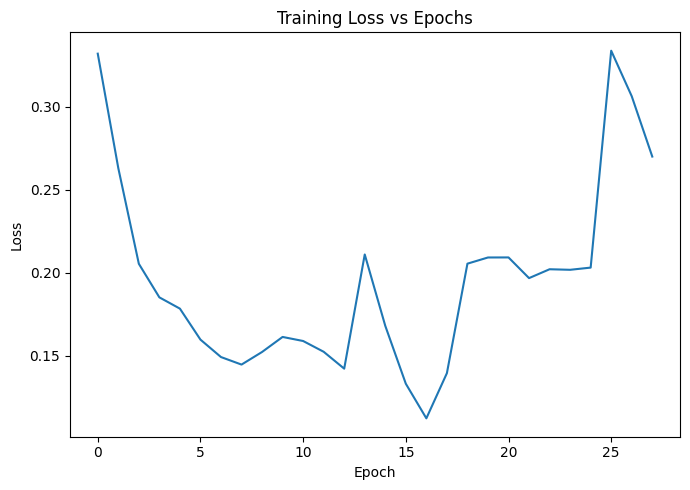


================ CLASSIFICATION REPORT ================

                precision    recall  f1-score   support

Advanced_Recon       0.79      0.73      0.76     22087
    Basic_Scan       0.82      0.87      0.84     32699
    High_Flood       1.00      1.00      1.00    154505
Protocol_Flood       1.00      1.00      1.00     45686

      accuracy                           0.96    254977
     macro avg       0.90      0.90      0.90    254977
  weighted avg       0.96      0.96      0.96    254977


================ MODEL PERFORMANCE ====================

Macro Average:
Precision: 0.9025
Recall:    0.8983
F1 Score:  0.9000

Weighted Average:
Precision: 0.9589
Recall:    0.9591
F1 Score:  0.9588

================ CONFUSION MATRIX =====================



<Figure size 800x600 with 0 Axes>

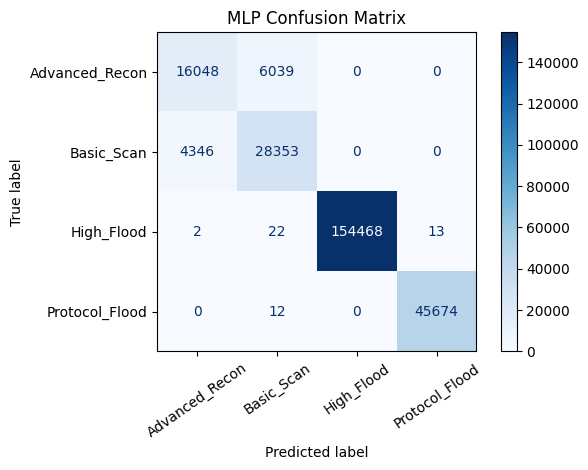


PHASE 2 COMPLETE


In [ ]:
# ============================================================
# PHASE 2: OFFLINE MLP BASELINE MODEL (EPOCH-BASED)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. DEFINE MODEL (EPOCH-BASED)
# ------------------------------------------------------------

print("\n[1] Building MLP model")

mlp_model = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    solver="adam",
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=200,          # epochs
    early_stopping=False,  # pure epoch training
    random_state=42,
    verbose=True
)

# ------------------------------------------------------------
# 2. TRAIN MODEL
# ------------------------------------------------------------

print("\n[2] Training model...")

mlp_model.fit(X_train_bal, y_train_bal)

print("\nTraining complete")
print(f"Epochs completed: {mlp_model.n_iter_}")
print(f"Final loss: {mlp_model.loss_:.6f}")

# ------------------------------------------------------------
# 3. LOSS CURVE
# ------------------------------------------------------------

plt.figure(figsize=(7,5))
plt.plot(mlp_model.loss_curve_)
plt.title("Training Loss vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. PREDICTIONS
# ------------------------------------------------------------

y_pred = mlp_model.predict(X_test_proc)
class_names = label_encoder.classes_

# ------------------------------------------------------------
# 5. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n================ CLASSIFICATION REPORT ================\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    zero_division=0
))

# ------------------------------------------------------------
# 6. MODEL PERFORMANCE (MACRO + WEIGHTED ONLY)
# ------------------------------------------------------------

print("\n================ MODEL PERFORMANCE ====================\n")

# Macro
precision_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)

# Weighted
precision_weighted = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall_weighted = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print("Macro Average:")
print(f"Precision: {precision_macro:.4f}")
print(f"Recall:    {recall_macro:.4f}")
print(f"F1 Score:  {f1_macro:.4f}\n")

print("Weighted Average:")
print(f"Precision: {precision_weighted:.4f}")
print(f"Recall:    {recall_weighted:.4f}")
print(f"F1 Score:  {f1_weighted:.4f}")

# ------------------------------------------------------------
# 7. CONFUSION MATRIX (ONLY ONE)
# ------------------------------------------------------------

print("\n================ CONFUSION MATRIX =====================\n")

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=35
)

plt.title("MLP Confusion Matrix")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print("\n===================================================")
print("PHASE 2 COMPLETE")
print("===================================================")

<h5><b>2.2 Gradinet Boosting Model</b></h5>

1. Model setup
2. Test Set Prediction
3. Classification Report Generation
4. Performance Evaluation (macro and weighted average)
5. Confusion Matrix Visualization


[1] Building Gradient Boosting baseline model

[2] Training Gradient Boosting model...


Training Gradient Boosting:   0%|          | 0/100 [00:00<?, ?it/s]


Training complete.
Total estimators trained: 100

[3] Making predictions...

================ CLASSIFICATION REPORT ================

                precision    recall  f1-score   support

Advanced_Recon       1.00      1.00      1.00     22087
    Basic_Scan       1.00      1.00      1.00     32699
    High_Flood       1.00      1.00      1.00    154505
Protocol_Flood       1.00      1.00      1.00     45686

      accuracy                           1.00    254977
     macro avg       1.00      1.00      1.00    254977
  weighted avg       1.00      1.00      1.00    254977


================ MODEL PERFORMANCE ====================

Macro Average:
Precision: 0.9987
Recall:    0.9991
F1 Score:  0.9989

Weighted Average:
Precision: 0.9995
Recall:    0.9995
F1 Score:  0.9995

================ CONFUSION MATRIX =====================



<Figure size 800x600 with 0 Axes>

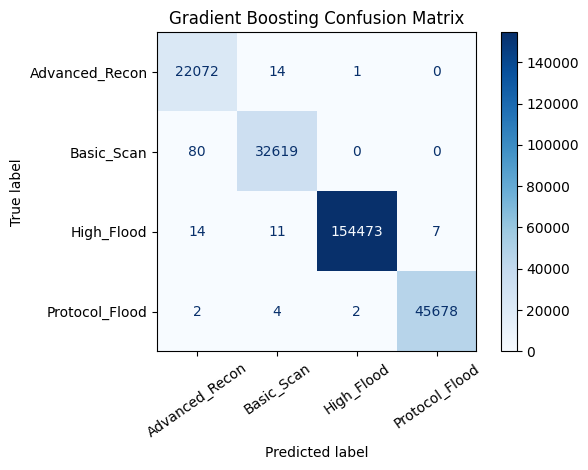


GRADIENT BOOSTING BASELINE COMPLETE

Key outputs:
gb_model
y_pred_gb
cm_gb


In [ ]:
# ============================================================
# PHASE 2B: OFFLINE GRADIENT BOOSTING BASELINE WITH TQDM
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from tqdm.notebook import tqdm

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. MODEL CONFIGURATION
# ------------------------------------------------------------

print("\n[1] Building Gradient Boosting baseline model")

N_ESTIMATORS = 100

gb_model = GradientBoostingClassifier(
    n_estimators=1,
    learning_rate=0.1,
    max_depth=3,
    subsample=1.0,
    random_state=42,
    warm_start=True
)

class_names = label_encoder.classes_

# ------------------------------------------------------------
# 2. TRAIN WITH TQDM PROGRESS BAR
# ------------------------------------------------------------

print("\n[2] Training Gradient Boosting model...")

for n in tqdm(range(1, N_ESTIMATORS + 1), desc="Training Gradient Boosting"):
    gb_model.set_params(n_estimators=n)
    gb_model.fit(X_train_bal, y_train_bal)

print("\nTraining complete.")
print(f"Total estimators trained: {gb_model.n_estimators}")

# ------------------------------------------------------------
# 3. PREDICTIONS
# ------------------------------------------------------------

print("\n[3] Making predictions...")

y_pred_gb = gb_model.predict(X_test_proc)

# ------------------------------------------------------------
# 4. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n================ CLASSIFICATION REPORT ================\n")

print(classification_report(
    y_test,
    y_pred_gb,
    target_names=class_names,
    zero_division=0
))

# ------------------------------------------------------------
# 5. MODEL PERFORMANCE: MACRO AND WEIGHTED ONLY
# ------------------------------------------------------------

print("\n================ MODEL PERFORMANCE ====================\n")

precision_macro_gb = precision_score(y_test, y_pred_gb, average="macro", zero_division=0)
recall_macro_gb = recall_score(y_test, y_pred_gb, average="macro", zero_division=0)
f1_macro_gb = f1_score(y_test, y_pred_gb, average="macro", zero_division=0)

precision_weighted_gb = precision_score(y_test, y_pred_gb, average="weighted", zero_division=0)
recall_weighted_gb = recall_score(y_test, y_pred_gb, average="weighted", zero_division=0)
f1_weighted_gb = f1_score(y_test, y_pred_gb, average="weighted", zero_division=0)

print("Macro Average:")
print(f"Precision: {precision_macro_gb:.4f}")
print(f"Recall:    {recall_macro_gb:.4f}")
print(f"F1 Score:  {f1_macro_gb:.4f}\n")

print("Weighted Average:")
print(f"Precision: {precision_weighted_gb:.4f}")
print(f"Recall:    {recall_weighted_gb:.4f}")
print(f"F1 Score:  {f1_weighted_gb:.4f}")

# ------------------------------------------------------------
# 6. CONFUSION MATRIX
# ------------------------------------------------------------

print("\n================ CONFUSION MATRIX =====================\n")

cm_gb = confusion_matrix(y_test, y_pred_gb)

plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_gb,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=35
)

plt.title("Gradient Boosting Confusion Matrix")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. FINAL SUMMARY
# ------------------------------------------------------------

print("\n===================================================")
print("GRADIENT BOOSTING BASELINE COMPLETE")
print("===================================================")

print("\nKey outputs:")
print("gb_model")
print("y_pred_gb")
print("cm_gb")

<h4><b>3. Phase 3: Online Models with Drift Detection</b></h4>

<h5><b>3.1 Adaptive Random Forest + ADWIN</b></h5>

1. Model Setup
2. Data Preparation
3. Training
4. Online Evaluation
5. Drift Detection
6. Performance Evaluation
7. Visualization


[1] Confirming inputs
X_train_proc shape: (1019908, 41)
y_train shape: (1019908,)
X_test_proc shape: (254977, 41)
y_test shape: (254977,)

Target classes:
Advanced_Recon
Basic_Scan
High_Flood
Protocol_Flood

[2] Preparing stream data

[3] Building Adaptive Random Forest model

[4] Warm-up training ARF on training stream


Warm-up training ARF:   0%|          | 0/1019908 [00:00<?, ?it/s]


Warm-up training complete.

[5] Starting online prequential evaluation


Online testing + learning ARF:   0%|          | 0/254977 [00:00<?, ?it/s]


DRIFT DETECTED at stream instance 181056 | ADWIN width: 29504.0 | Estimated error rate: 0.0174

DRIFT DETECTED at stream instance 190784 | ADWIN width: 8704.0 | Estimated error rate: 0.0192

Online evaluation complete.

================ CLASSIFICATION REPORT ================

                precision    recall  f1-score   support

Advanced_Recon       0.99      0.81      0.89     22087
    Basic_Scan       0.88      1.00      0.94     32699
    High_Flood       1.00      1.00      1.00    154505
Protocol_Flood       1.00      1.00      1.00     45686

      accuracy                           0.98    254977
     macro avg       0.97      0.95      0.96    254977
  weighted avg       0.98      0.98      0.98    254977


================ MODEL PERFORMANCE ====================

Macro Average:
Precision: 0.9688
Recall:    0.9502
F1 Score:  0.9563

Weighted Average:
Precision: 0.9842
Recall:    0.9825
F1 Score:  0.9821

================ DRIFT SUMMARY ========================

Total drift e

<Figure size 800x600 with 0 Axes>

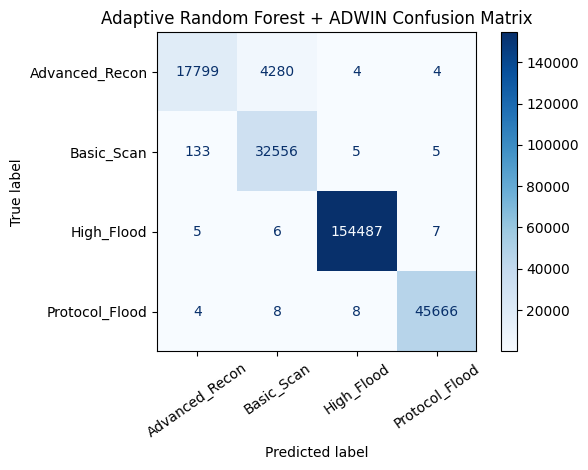

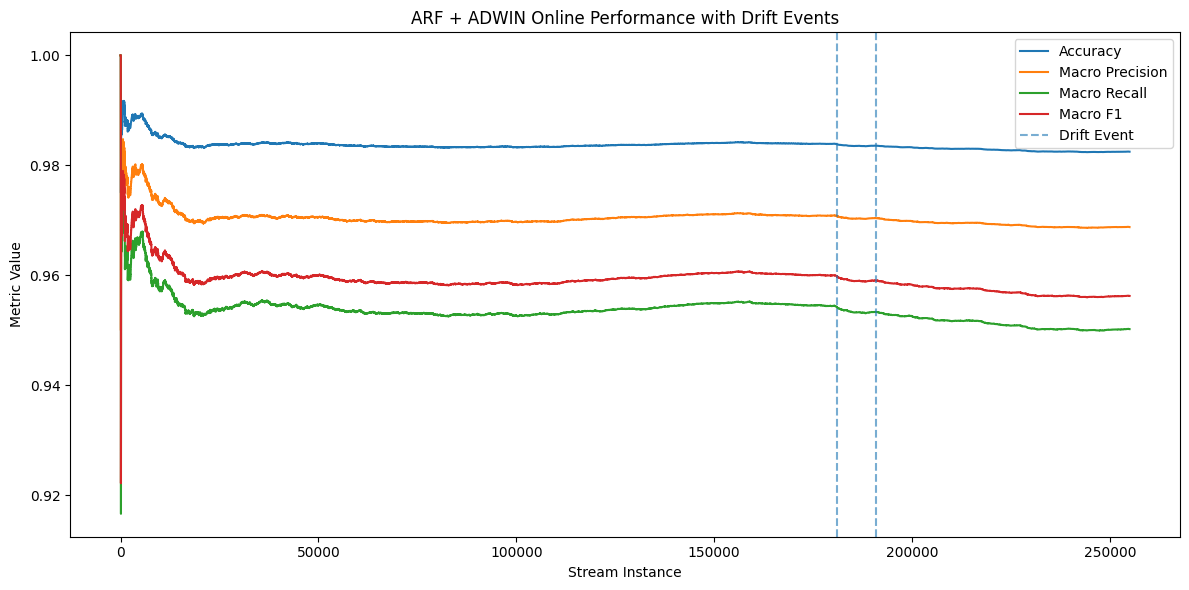

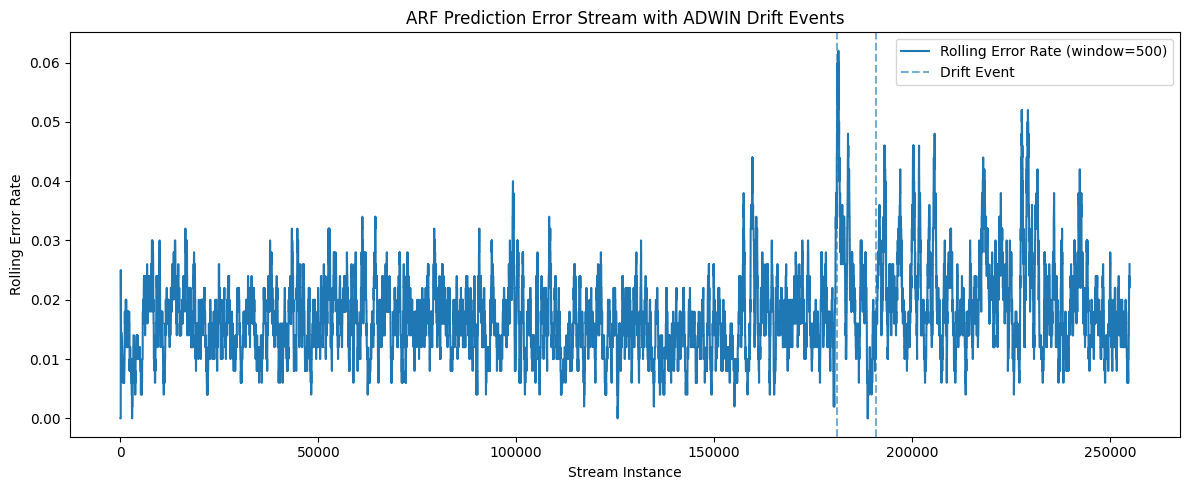


PHASE 3A COMPLETE: ARF + ADWIN


In [ ]:
# ============================================================
# PHASE 3A: ONLINE ADAPTIVE RANDOM FOREST WITH ADWIN
# ============================================================

# If needed:
# !pip install river tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.notebook import tqdm

from river import forest
from river import drift
from river import metrics

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. CONFIRM INPUTS
# ------------------------------------------------------------

print("\n[1] Confirming inputs")

print(f"X_train_proc shape: {X_train_proc.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test_proc shape: {X_test_proc.shape}")
print(f"y_test shape: {y_test.shape}")

class_names = label_encoder.classes_

print("\nTarget classes:")
for cls in class_names:
    print(cls)

# ------------------------------------------------------------
# 2. PREPARE STREAM DATA
# ------------------------------------------------------------

print("\n[2] Preparing stream data")

feature_names = [f"feature_{i}" for i in range(X_train_proc.shape[1])]

X_train_stream = pd.DataFrame(X_train_proc, columns=feature_names)
X_test_stream = pd.DataFrame(X_test_proc, columns=feature_names)

y_train_stream = pd.Series(y_train)
y_test_stream = pd.Series(y_test)

# ------------------------------------------------------------
# 3. DEFINE ARF + ADWIN MODEL
# ------------------------------------------------------------

print("\n[3] Building Adaptive Random Forest model")

arf_model = forest.ARFClassifier(
    n_models=10,
    max_features="sqrt",
    lambda_value=6,
    metric=metrics.Accuracy(),
    drift_detector=drift.ADWIN(delta=0.002),
    warning_detector=drift.ADWIN(delta=0.01),
    seed=42
)

# Reliable external ADWIN drift detector on prediction-error stream
adwin_detector_arf = drift.ADWIN(delta=0.002)

# ------------------------------------------------------------
# 4. WARM-UP TRAINING
# ------------------------------------------------------------

print("\n[4] Warm-up training ARF on training stream")

for x, y in tqdm(
    zip(X_train_stream.to_dict(orient="records"), y_train_stream),
    total=len(y_train_stream),
    desc="Warm-up training ARF"
):
    arf_model.learn_one(x, int(y))

print("\nWarm-up training complete.")

# ------------------------------------------------------------
# 5. ONLINE PREQUENTIAL TESTING + LEARNING
# ------------------------------------------------------------

print("\n[5] Starting online prequential evaluation")

online_accuracy_arf = metrics.Accuracy()
online_precision_arf = metrics.MacroPrecision()
online_recall_arf = metrics.MacroRecall()
online_f1_arf = metrics.MacroF1()

y_true_arf = []
y_pred_arf = []

accuracy_history_arf = []
precision_history_arf = []
recall_history_arf = []
f1_history_arf = []
error_history_arf = []

drift_points_arf = []
drift_widths_arf = []
drift_error_rates_arf = []

for i, (x, y_true) in enumerate(
    tqdm(
        zip(X_test_stream.to_dict(orient="records"), y_test_stream),
        total=len(y_test_stream),
        desc="Online testing + learning ARF"
    ),
    start=1
):
    y_true = int(y_true)

    # Predict before learning
    y_pred = arf_model.predict_one(x)

    if y_pred is None:
        y_pred = 0

    y_pred = int(y_pred)

    y_true_arf.append(y_true)
    y_pred_arf.append(y_pred)

    # Update online metrics
    online_accuracy_arf.update(y_true, y_pred)
    online_precision_arf.update(y_true, y_pred)
    online_recall_arf.update(y_true, y_pred)
    online_f1_arf.update(y_true, y_pred)

    accuracy_history_arf.append(online_accuracy_arf.get())
    precision_history_arf.append(online_precision_arf.get())
    recall_history_arf.append(online_recall_arf.get())
    f1_history_arf.append(online_f1_arf.get())

    # External ADWIN drift detection using prediction error
    error = int(y_pred != y_true)
    error_history_arf.append(error)

    adwin_detector_arf.update(error)

    if adwin_detector_arf.drift_detected:
        drift_points_arf.append(i)
        drift_widths_arf.append(adwin_detector_arf.width)
        drift_error_rates_arf.append(adwin_detector_arf.estimation)

        print(
            f"\nDRIFT DETECTED at stream instance {i} | "
            f"ADWIN width: {adwin_detector_arf.width} | "
            f"Estimated error rate: {adwin_detector_arf.estimation:.4f}"
        )

    # Learn after prediction
    arf_model.learn_one(x, y_true)

print("\nOnline evaluation complete.")

# ------------------------------------------------------------
# 6. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n================ CLASSIFICATION REPORT ================\n")

print(classification_report(
    y_true_arf,
    y_pred_arf,
    target_names=class_names,
    zero_division=0
))

# ------------------------------------------------------------
# 7. MODEL PERFORMANCE: MACRO + WEIGHTED
# ------------------------------------------------------------

print("\n================ MODEL PERFORMANCE ====================\n")

precision_macro_arf = precision_score(
    y_true_arf, y_pred_arf, average="macro", zero_division=0
)

recall_macro_arf = recall_score(
    y_true_arf, y_pred_arf, average="macro", zero_division=0
)

f1_macro_arf = f1_score(
    y_true_arf, y_pred_arf, average="macro", zero_division=0
)

precision_weighted_arf = precision_score(
    y_true_arf, y_pred_arf, average="weighted", zero_division=0
)

recall_weighted_arf = recall_score(
    y_true_arf, y_pred_arf, average="weighted", zero_division=0
)

f1_weighted_arf = f1_score(
    y_true_arf, y_pred_arf, average="weighted", zero_division=0
)

print("Macro Average:")
print(f"Precision: {precision_macro_arf:.4f}")
print(f"Recall:    {recall_macro_arf:.4f}")
print(f"F1 Score:  {f1_macro_arf:.4f}")

print("\nWeighted Average:")
print(f"Precision: {precision_weighted_arf:.4f}")
print(f"Recall:    {recall_weighted_arf:.4f}")
print(f"F1 Score:  {f1_weighted_arf:.4f}")

# ------------------------------------------------------------
# 8. DRIFT SUMMARY
# ------------------------------------------------------------

print("\n================ DRIFT SUMMARY ========================\n")

print(f"Total drift events detected: {len(drift_points_arf)}")

if len(drift_points_arf) > 0:
    for idx, point in enumerate(drift_points_arf):
        print(
            f"Drift {idx + 1}: "
            f"Instance={point}, "
            f"ADWIN width={drift_widths_arf[idx]}, "
            f"Estimated error={drift_error_rates_arf[idx]:.4f}"
        )
else:
    print("No drift events detected.")

# ------------------------------------------------------------
# 9. CONFUSION MATRIX
# ------------------------------------------------------------

print("\n================ CONFUSION MATRIX =====================\n")

cm_arf = confusion_matrix(y_true_arf, y_pred_arf)

plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_arf,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=35
)

plt.title("Adaptive Random Forest + ADWIN Confusion Matrix")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. ONLINE PERFORMANCE VISUALIZATION WITH DRIFT EVENTS
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(accuracy_history_arf, label="Accuracy")
plt.plot(precision_history_arf, label="Macro Precision")
plt.plot(recall_history_arf, label="Macro Recall")
plt.plot(f1_history_arf, label="Macro F1")

for drift_point in drift_points_arf:
    plt.axvline(
        x=drift_point,
        linestyle="--",
        alpha=0.6,
        label="Drift Event" if drift_point == drift_points_arf[0] else None
    )

plt.title("ARF + ADWIN Online Performance with Drift Events")
plt.xlabel("Stream Instance")
plt.ylabel("Metric Value")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. ERROR STREAM VISUALIZATION WITH DRIFT EVENTS
# ------------------------------------------------------------

rolling_window = 500

rolling_error_arf = pd.Series(error_history_arf).rolling(
    window=rolling_window,
    min_periods=1
).mean()

plt.figure(figsize=(12, 5))

plt.plot(
    rolling_error_arf,
    label=f"Rolling Error Rate (window={rolling_window})"
)

for drift_point in drift_points_arf:
    plt.axvline(
        x=drift_point,
        linestyle="--",
        alpha=0.6,
        label="Drift Event" if drift_point == drift_points_arf[0] else None
    )

plt.title("ARF Prediction Error Stream with ADWIN Drift Events")
plt.xlabel("Stream Instance")
plt.ylabel("Rolling Error Rate")
plt.legend()
plt.tight_layout()
plt.show()


print("\n===================================================")
print("PHASE 3A COMPLETE: ARF + ADWIN")
print("===================================================")

<h5><b>3.2 Streaming Random Patched (SRM) + ADWIN</b></h5>

1. Model Setup
2. Data Preparation
3. Training
4. Online Evaluation
5. Drift Detection
6. Performance Evaluation
7. Visualization


[1] Confirming inputs
X_train_proc shape: (1019908, 41)
y_train shape: (1019908,)
X_test_proc shape: (254977, 41)
y_test shape: (254977,)

Target classes:
Advanced_Recon
Basic_Scan
High_Flood
Protocol_Flood

[2] Preparing stream data

[3] Building Streaming Random Patches model

[4] Warm-up training SRP on training stream


Warm-up training SRP:   0%|          | 0/1019908 [00:00<?, ?it/s]


Warm-up training complete.

[5] Starting online prequential evaluation


Online testing + learning SRP:   0%|          | 0/254977 [00:00<?, ?it/s]


Online evaluation complete.

================ CLASSIFICATION REPORT ================

                precision    recall  f1-score   support

Advanced_Recon       0.85      0.07      0.13     22087
    Basic_Scan       0.61      0.99      0.76     32699
    High_Flood       1.00      1.00      1.00    154505
Protocol_Flood       1.00      1.00      1.00     45686

      accuracy                           0.92    254977
     macro avg       0.87      0.77      0.72    254977
  weighted avg       0.94      0.92      0.89    254977


================ MODEL PERFORMANCE ====================

Macro Average:
Precision: 0.8660
Recall:    0.7656
F1 Score:  0.7223

Weighted Average:
Precision: 0.9373
Recall:    0.9183
F1 Score:  0.8935

================ DRIFT SUMMARY ========================

Total drift events detected: 0
No drift events detected.

================ CONFUSION MATRIX =====================



<Figure size 800x600 with 0 Axes>

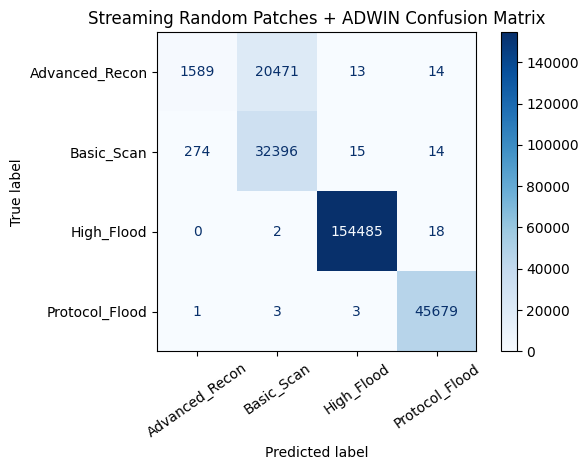

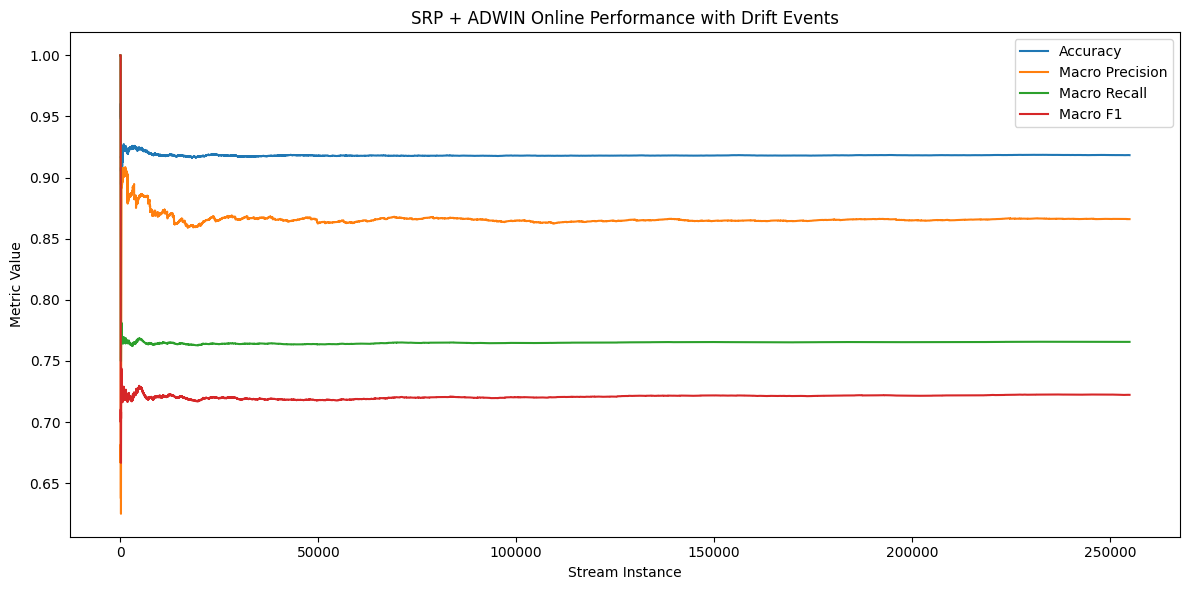

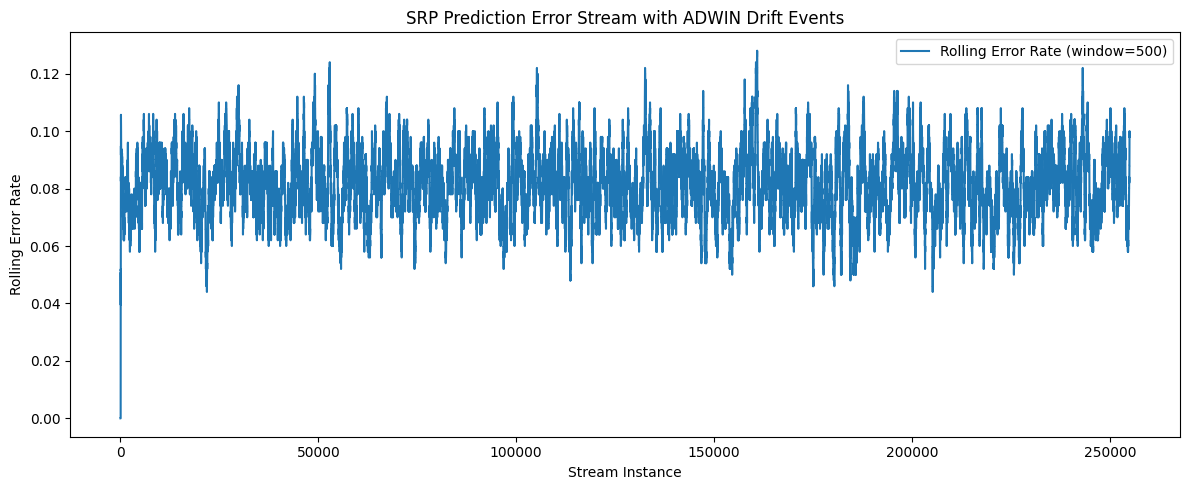


PHASE 3C COMPLETE: SRP + ADWIN


In [ ]:
# ============================================================
# PHASE 3B: ONLINE STREAMING RANDOM PATCHES WITH ADWIN
# ============================================================

# If needed:
# !pip install river tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.notebook import tqdm

from river import ensemble
from river import drift
from river import metrics

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. CONFIRM INPUTS
# ------------------------------------------------------------

print("\n[1] Confirming inputs")

print(f"X_train_proc shape: {X_train_proc.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test_proc shape: {X_test_proc.shape}")
print(f"y_test shape: {y_test.shape}")

class_names = label_encoder.classes_

print("\nTarget classes:")
for cls in class_names:
    print(cls)

# ------------------------------------------------------------
# 2. PREPARE STREAM DATA
# ------------------------------------------------------------

print("\n[2] Preparing stream data")

feature_names = [f"feature_{i}" for i in range(X_train_proc.shape[1])]

X_train_stream = pd.DataFrame(X_train_proc, columns=feature_names)
X_test_stream = pd.DataFrame(X_test_proc, columns=feature_names)

y_train_stream = pd.Series(y_train)
y_test_stream = pd.Series(y_test)

# ------------------------------------------------------------
# 3. DEFINE SRP + ADWIN MODEL
# ------------------------------------------------------------

print("\n[3] Building Streaming Random Patches model")

srp_model = ensemble.SRPClassifier(
    n_models=10,
    subspace_size="sqrt",
    training_method="patches",
    lam=6,
    drift_detector=drift.ADWIN(delta=0.002),
    warning_detector=drift.ADWIN(delta=0.01),
    seed=42
)

adwin_detector_srp = drift.ADWIN(delta=0.002)

# ------------------------------------------------------------
# 4. WARM-UP TRAINING
# ------------------------------------------------------------

print("\n[4] Warm-up training SRP on training stream")

for x, y in tqdm(
    zip(X_train_stream.to_dict(orient="records"), y_train_stream),
    total=len(y_train_stream),
    desc="Warm-up training SRP"
):
    srp_model.learn_one(x, int(y))

print("\nWarm-up training complete.")

# ------------------------------------------------------------
# 5. ONLINE PREQUENTIAL TESTING + LEARNING
# ------------------------------------------------------------

print("\n[5] Starting online prequential evaluation")

online_accuracy_srp = metrics.Accuracy()
online_precision_srp = metrics.MacroPrecision()
online_recall_srp = metrics.MacroRecall()
online_f1_srp = metrics.MacroF1()

y_true_srp = []
y_pred_srp = []

accuracy_history_srp = []
precision_history_srp = []
recall_history_srp = []
f1_history_srp = []
error_history_srp = []

drift_points_srp = []
drift_widths_srp = []
drift_error_rates_srp = []

for i, (x, y_true) in enumerate(
    tqdm(
        zip(X_test_stream.to_dict(orient="records"), y_test_stream),
        total=len(y_test_stream),
        desc="Online testing + learning SRP"
    ),
    start=1
):
    y_true = int(y_true)

    y_pred = srp_model.predict_one(x)

    if y_pred is None:
        y_pred = 0

    y_pred = int(y_pred)

    y_true_srp.append(y_true)
    y_pred_srp.append(y_pred)

    online_accuracy_srp.update(y_true, y_pred)
    online_precision_srp.update(y_true, y_pred)
    online_recall_srp.update(y_true, y_pred)
    online_f1_srp.update(y_true, y_pred)

    accuracy_history_srp.append(online_accuracy_srp.get())
    precision_history_srp.append(online_precision_srp.get())
    recall_history_srp.append(online_recall_srp.get())
    f1_history_srp.append(online_f1_srp.get())

    error = int(y_pred != y_true)
    error_history_srp.append(error)

    adwin_detector_srp.update(error)

    if adwin_detector_srp.drift_detected:
        drift_points_srp.append(i)
        drift_widths_srp.append(adwin_detector_srp.width)
        drift_error_rates_srp.append(adwin_detector_srp.estimation)

        print(
            f"\nDRIFT DETECTED at stream instance {i} | "
            f"ADWIN width: {adwin_detector_srp.width} | "
            f"Estimated error rate: {adwin_detector_srp.estimation:.4f}"
        )

    srp_model.learn_one(x, y_true)

print("\nOnline evaluation complete.")

# ------------------------------------------------------------
# 6. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n================ CLASSIFICATION REPORT ================\n")

print(classification_report(
    y_true_srp,
    y_pred_srp,
    target_names=class_names,
    zero_division=0
))

# ------------------------------------------------------------
# 7. MODEL PERFORMANCE: MACRO + WEIGHTED
# ------------------------------------------------------------

print("\n================ MODEL PERFORMANCE ====================\n")

precision_macro_srp = precision_score(
    y_true_srp, y_pred_srp, average="macro", zero_division=0
)

recall_macro_srp = recall_score(
    y_true_srp, y_pred_srp, average="macro", zero_division=0
)

f1_macro_srp = f1_score(
    y_true_srp, y_pred_srp, average="macro", zero_division=0
)

precision_weighted_srp = precision_score(
    y_true_srp, y_pred_srp, average="weighted", zero_division=0
)

recall_weighted_srp = recall_score(
    y_true_srp, y_pred_srp, average="weighted", zero_division=0
)

f1_weighted_srp = f1_score(
    y_true_srp, y_pred_srp, average="weighted", zero_division=0
)

print("Macro Average:")
print(f"Precision: {precision_macro_srp:.4f}")
print(f"Recall:    {recall_macro_srp:.4f}")
print(f"F1 Score:  {f1_macro_srp:.4f}")

print("\nWeighted Average:")
print(f"Precision: {precision_weighted_srp:.4f}")
print(f"Recall:    {recall_weighted_srp:.4f}")
print(f"F1 Score:  {f1_weighted_srp:.4f}")

# ------------------------------------------------------------
# 8. DRIFT SUMMARY
# ------------------------------------------------------------

print("\n================ DRIFT SUMMARY ========================\n")

print(f"Total drift events detected: {len(drift_points_srp)}")

if len(drift_points_srp) > 0:
    for idx, point in enumerate(drift_points_srp):
        print(
            f"Drift {idx + 1}: "
            f"Instance={point}, "
            f"ADWIN width={drift_widths_srp[idx]}, "
            f"Estimated error={drift_error_rates_srp[idx]:.4f}"
        )
else:
    print("No drift events detected.")

# ------------------------------------------------------------
# 9. CONFUSION MATRIX
# ------------------------------------------------------------

print("\n================ CONFUSION MATRIX =====================\n")

cm_srp = confusion_matrix(y_true_srp, y_pred_srp)

plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_srp,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=35
)

plt.title("Streaming Random Patches + ADWIN Confusion Matrix")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. ONLINE PERFORMANCE VISUALIZATION WITH DRIFT EVENTS
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(accuracy_history_srp, label="Accuracy")
plt.plot(precision_history_srp, label="Macro Precision")
plt.plot(recall_history_srp, label="Macro Recall")
plt.plot(f1_history_srp, label="Macro F1")

for drift_point in drift_points_srp:
    plt.axvline(
        x=drift_point,
        linestyle="--",
        alpha=0.6,
        label="Drift Event" if drift_point == drift_points_srp[0] else None
    )

plt.title("SRP + ADWIN Online Performance with Drift Events")
plt.xlabel("Stream Instance")
plt.ylabel("Metric Value")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. ERROR STREAM VISUALIZATION WITH DRIFT EVENTS
# ------------------------------------------------------------

rolling_window = 500

rolling_error_srp = pd.Series(error_history_srp).rolling(
    window=rolling_window,
    min_periods=1
).mean()

plt.figure(figsize=(12, 5))

plt.plot(
    rolling_error_srp,
    label=f"Rolling Error Rate (window={rolling_window})"
)

for drift_point in drift_points_srp:
    plt.axvline(
        x=drift_point,
        linestyle="--",
        alpha=0.6,
        label="Drift Event" if drift_point == drift_points_srp[0] else None
    )

plt.title("SRP Prediction Error Stream with ADWIN Drift Events")
plt.xlabel("Stream Instance")
plt.ylabel("Rolling Error Rate")
plt.legend()
plt.tight_layout()
plt.show()


print("\n===================================================")
print("PHASE 3C COMPLETE: SRP + ADWIN")
print("===================================================")

<h4><b>4. Hybrid Model</b></h4>
<h5><b>Gradient Boosting Offline + ARF Online with ADWIN</b></h5>

1. Hybrid Model Setup
2. Data Preparation
3. Online Component Training
4. Hybrid Prediction (Offline + Online)
5. Online Evaluation
6. Drift Detection
7. Performance Evaluation
8. Visualization


[1] Initializing Hybrid Model
Offline model weight: 0.6
Online model weight:  0.4

[2] Warm-up training ARF component


Warm-up ARF:   0%|          | 0/1019908 [00:00<?, ?it/s]

ARF warm-up complete.

[3] Starting hybrid online evaluation


Hybrid prediction + online learning:   0%|          | 0/254977 [00:00<?, ?it/s]


Hybrid evaluation complete.

================ CLASSIFICATION REPORT ================

                precision    recall  f1-score   support

Advanced_Recon       1.00      1.00      1.00     22087
    Basic_Scan       1.00      1.00      1.00     32699
    High_Flood       1.00      1.00      1.00    154505
Protocol_Flood       1.00      1.00      1.00     45686

      accuracy                           1.00    254977
     macro avg       1.00      1.00      1.00    254977
  weighted avg       1.00      1.00      1.00    254977


================ MODEL PERFORMANCE ====================

Macro Average:
Precision: 0.9991
Recall:    0.9993
F1 Score:  0.9992

Weighted Average:
Precision: 0.9996
Recall:    0.9996
F1 Score:  0.9996

================ DRIFT SUMMARY ========================

Total drift events detected: 0
No drift events detected.

================ CONFUSION MATRIX =====================



<Figure size 800x600 with 0 Axes>

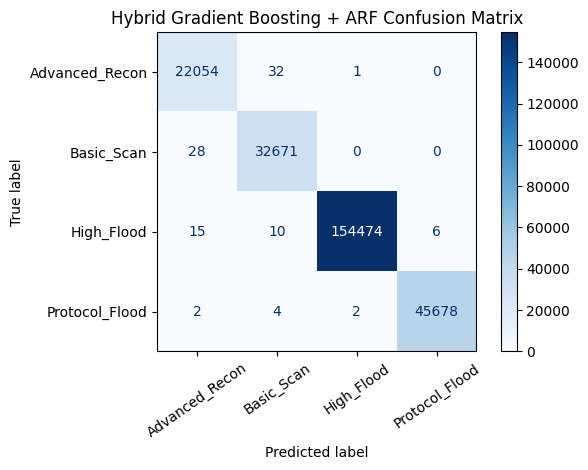

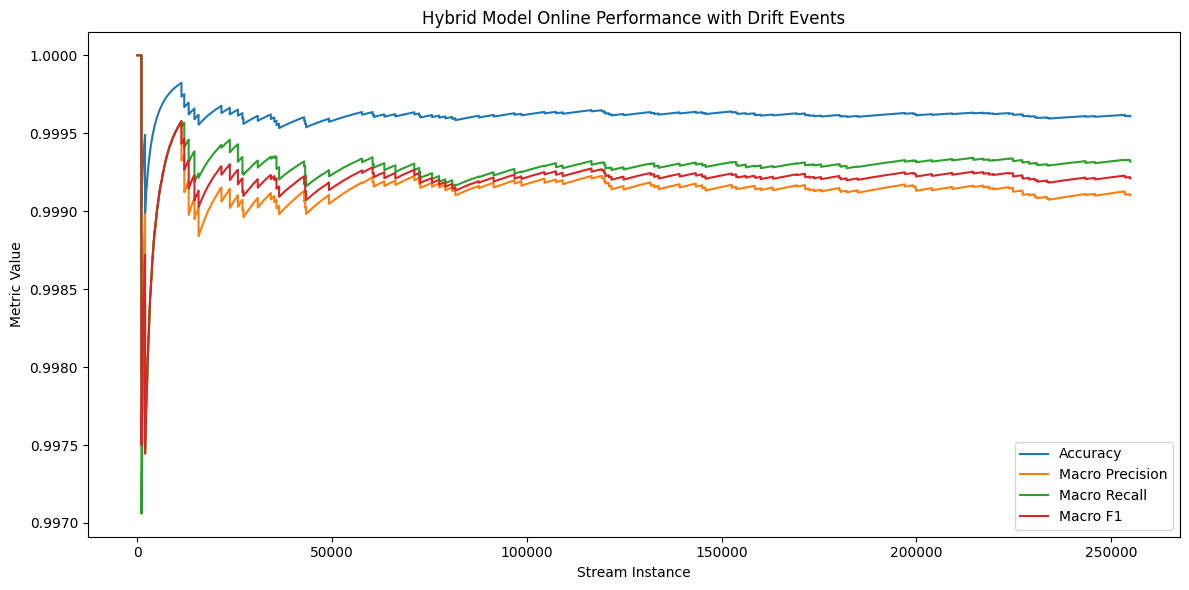

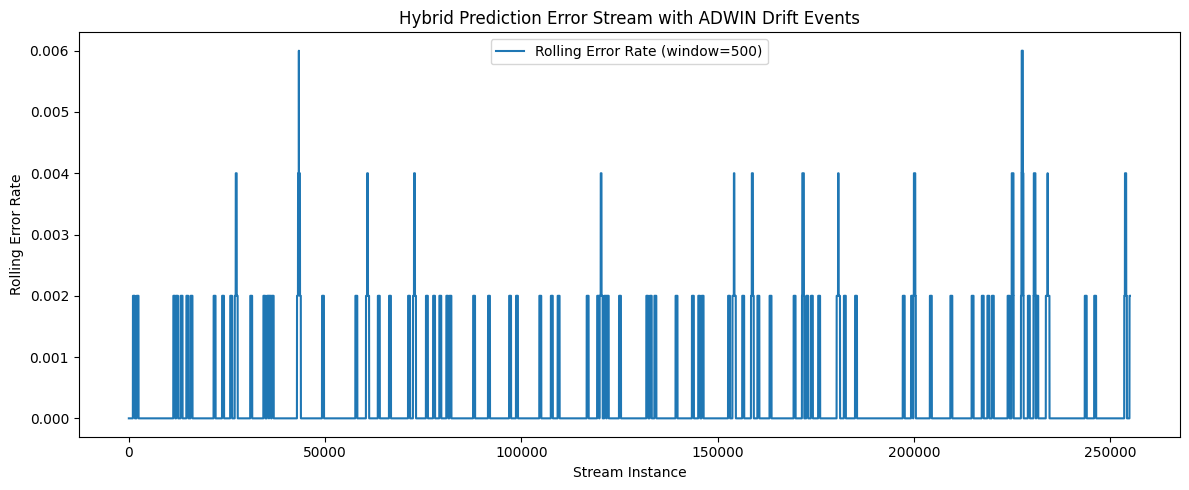


PHASE 4 COMPLETE: HYBRID OFFLINE-ONLINE MODEL


In [ ]:
# ============================================================
# PHASE 4: HYBRID MODEL
# Gradient Boosting Offline + ARF Online with ADWIN
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.notebook import tqdm

from river import forest
from river import drift
from river import metrics

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

print("\n[1] Initializing Hybrid Model")

class_names = label_encoder.classes_
n_classes = len(class_names)

# Weighting between offline and online models
OFFLINE_WEIGHT = 0.60   # Gradient Boosting
ONLINE_WEIGHT = 0.40    # ARF

print(f"Offline model weight: {OFFLINE_WEIGHT}")
print(f"Online model weight:  {ONLINE_WEIGHT}")

# ------------------------------------------------------------
# 2. PREPARE STREAM DATA FOR ARF
# ------------------------------------------------------------

feature_names = [f"feature_{i}" for i in range(X_train_proc.shape[1])]

X_train_stream = pd.DataFrame(X_train_proc, columns=feature_names)
X_test_stream = pd.DataFrame(X_test_proc, columns=feature_names)

y_train_stream = pd.Series(y_train)
y_test_stream = pd.Series(y_test)

# ------------------------------------------------------------
# 3. DEFINE ONLINE ARF COMPONENT
# ------------------------------------------------------------

hybrid_arf = forest.ARFClassifier(
    n_models=10,
    max_features="sqrt",
    lambda_value=6,
    metric=metrics.Accuracy(),
    drift_detector=drift.ADWIN(delta=0.002),
    warning_detector=drift.ADWIN(delta=0.01),
    seed=42
)

adwin_detector_hybrid = drift.ADWIN(delta=0.002)

# ------------------------------------------------------------
# 4. WARM-UP TRAINING FOR ONLINE COMPONENT
# ------------------------------------------------------------

print("\n[2] Warm-up training ARF component")

for x, y in tqdm(
    zip(X_train_stream.to_dict(orient="records"), y_train_stream),
    total=len(y_train_stream),
    desc="Warm-up ARF"
):
    hybrid_arf.learn_one(x, int(y))

print("ARF warm-up complete.")

# ------------------------------------------------------------
# 5. HYBRID PREQUENTIAL EVALUATION
# ------------------------------------------------------------

print("\n[3] Starting hybrid online evaluation")

hybrid_accuracy_metric = metrics.Accuracy()
hybrid_precision_metric = metrics.MacroPrecision()
hybrid_recall_metric = metrics.MacroRecall()
hybrid_f1_metric = metrics.MacroF1()

y_true_hybrid = []
y_pred_hybrid = []

accuracy_history_hybrid = []
precision_history_hybrid = []
recall_history_hybrid = []
f1_history_hybrid = []
error_history_hybrid = []

drift_points_hybrid = []
drift_widths_hybrid = []
drift_error_rates_hybrid = []

for i, (x_river, x_sklearn, y_true) in enumerate(
    tqdm(
        zip(
            X_test_stream.to_dict(orient="records"),
            X_test_proc,
            y_test_stream
        ),
        total=len(y_test_stream),
        desc="Hybrid prediction + online learning"
    ),
    start=1
):
    y_true = int(y_true)

    # --------------------------------------------------------
    # Offline Gradient Boosting probability
    # --------------------------------------------------------

    offline_proba = gb_model.predict_proba(
        x_sklearn.reshape(1, -1)
    )[0]

    # --------------------------------------------------------
    # Online ARF probability
    # --------------------------------------------------------

    online_proba_dict = hybrid_arf.predict_proba_one(x_river)

    online_proba = np.zeros(n_classes)

    if online_proba_dict is not None:
        for cls, prob in online_proba_dict.items():
            online_proba[int(cls)] = prob

    # If ARF gives no probabilities, rely fully on offline model
    if online_proba.sum() == 0:
        hybrid_proba = offline_proba
    else:
        hybrid_proba = (
            OFFLINE_WEIGHT * offline_proba +
            ONLINE_WEIGHT * online_proba
        )

    y_pred = int(np.argmax(hybrid_proba))

    # --------------------------------------------------------
    # Store and evaluate prediction
    # --------------------------------------------------------

    y_true_hybrid.append(y_true)
    y_pred_hybrid.append(y_pred)

    hybrid_accuracy_metric.update(y_true, y_pred)
    hybrid_precision_metric.update(y_true, y_pred)
    hybrid_recall_metric.update(y_true, y_pred)
    hybrid_f1_metric.update(y_true, y_pred)

    accuracy_history_hybrid.append(hybrid_accuracy_metric.get())
    precision_history_hybrid.append(hybrid_precision_metric.get())
    recall_history_hybrid.append(hybrid_recall_metric.get())
    f1_history_hybrid.append(hybrid_f1_metric.get())

    # --------------------------------------------------------
    # ADWIN drift detection on hybrid prediction error
    # --------------------------------------------------------

    error = int(y_pred != y_true)
    error_history_hybrid.append(error)

    adwin_detector_hybrid.update(error)

    if adwin_detector_hybrid.drift_detected:
        drift_points_hybrid.append(i)
        drift_widths_hybrid.append(adwin_detector_hybrid.width)
        drift_error_rates_hybrid.append(adwin_detector_hybrid.estimation)

        print(
            f"\nDRIFT DETECTED at stream instance {i} | "
            f"ADWIN width: {adwin_detector_hybrid.width} | "
            f"Estimated error rate: {adwin_detector_hybrid.estimation:.4f}"
        )

    # --------------------------------------------------------
    # Online update
    # --------------------------------------------------------

    hybrid_arf.learn_one(x_river, y_true)

print("\nHybrid evaluation complete.")

# ------------------------------------------------------------
# 6. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n================ CLASSIFICATION REPORT ================\n")

print(classification_report(
    y_true_hybrid,
    y_pred_hybrid,
    target_names=class_names,
    zero_division=0
))

# ------------------------------------------------------------
# 7. MODEL PERFORMANCE: MACRO + WEIGHTED
# ------------------------------------------------------------

print("\n================ MODEL PERFORMANCE ====================\n")

precision_macro_hybrid = precision_score(
    y_true_hybrid,
    y_pred_hybrid,
    average="macro",
    zero_division=0
)

recall_macro_hybrid = recall_score(
    y_true_hybrid,
    y_pred_hybrid,
    average="macro",
    zero_division=0
)

f1_macro_hybrid = f1_score(
    y_true_hybrid,
    y_pred_hybrid,
    average="macro",
    zero_division=0
)

precision_weighted_hybrid = precision_score(
    y_true_hybrid,
    y_pred_hybrid,
    average="weighted",
    zero_division=0
)

recall_weighted_hybrid = recall_score(
    y_true_hybrid,
    y_pred_hybrid,
    average="weighted",
    zero_division=0
)

f1_weighted_hybrid = f1_score(
    y_true_hybrid,
    y_pred_hybrid,
    average="weighted",
    zero_division=0
)

print("Macro Average:")
print(f"Precision: {precision_macro_hybrid:.4f}")
print(f"Recall:    {recall_macro_hybrid:.4f}")
print(f"F1 Score:  {f1_macro_hybrid:.4f}")

print("\nWeighted Average:")
print(f"Precision: {precision_weighted_hybrid:.4f}")
print(f"Recall:    {recall_weighted_hybrid:.4f}")
print(f"F1 Score:  {f1_weighted_hybrid:.4f}")

# ------------------------------------------------------------
# 8. DRIFT SUMMARY
# ------------------------------------------------------------

print("\n================ DRIFT SUMMARY ========================\n")

print(f"Total drift events detected: {len(drift_points_hybrid)}")

if len(drift_points_hybrid) > 0:
    for idx, point in enumerate(drift_points_hybrid):
        print(
            f"Drift {idx + 1}: "
            f"Instance={point}, "
            f"ADWIN width={drift_widths_hybrid[idx]}, "
            f"Estimated error={drift_error_rates_hybrid[idx]:.4f}"
        )
else:
    print("No drift events detected.")

# ------------------------------------------------------------
# 9. CONFUSION MATRIX
# ------------------------------------------------------------

print("\n================ CONFUSION MATRIX =====================\n")

cm_hybrid = confusion_matrix(y_true_hybrid, y_pred_hybrid)

plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_hybrid,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=35
)

plt.title("Hybrid Gradient Boosting + ARF Confusion Matrix")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. ONLINE PERFORMANCE VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(accuracy_history_hybrid, label="Accuracy")
plt.plot(precision_history_hybrid, label="Macro Precision")
plt.plot(recall_history_hybrid, label="Macro Recall")
plt.plot(f1_history_hybrid, label="Macro F1")

for drift_point in drift_points_hybrid:
    plt.axvline(
        x=drift_point,
        linestyle="--",
        alpha=0.6,
        label="Drift Event" if drift_point == drift_points_hybrid[0] else None
    )

plt.title("Hybrid Model Online Performance with Drift Events")
plt.xlabel("Stream Instance")
plt.ylabel("Metric Value")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. ERROR STREAM VISUALIZATION
# ------------------------------------------------------------

rolling_window = 500

rolling_error_hybrid = pd.Series(error_history_hybrid).rolling(
    window=rolling_window,
    min_periods=1
).mean()

plt.figure(figsize=(12, 5))

plt.plot(
    rolling_error_hybrid,
    label=f"Rolling Error Rate (window={rolling_window})"
)

for drift_point in drift_points_hybrid:
    plt.axvline(
        x=drift_point,
        linestyle="--",
        alpha=0.6,
        label="Drift Event" if drift_point == drift_points_hybrid[0] else None
    )

plt.title("Hybrid Prediction Error Stream with ADWIN Drift Events")
plt.xlabel("Stream Instance")
plt.ylabel("Rolling Error Rate")
plt.legend()
plt.tight_layout()
plt.show()


print("\n===================================================")
print("PHASE 4 COMPLETE: HYBRID OFFLINE-ONLINE MODEL")
print("===================================================")